## Visualizing Tech Stocks

In this project you will analyze and visualize the top 5 highest valued technology stocks, as of the end of the first half of 2023:
* Microsoft (NASDAQ:MSFT)
* Amazon (NASDAQ:AMZN)
* Apple (NASDAQ:AAPL)
* Alphabet (NASDAQ:GOOGL)
* Meta (NASDAQ:META).

Using Pandas, yfinance, and Matplotlib, you will take a visual look into the similarities and differences between these stocks during the six month period from January through June 2023. In your analysis you will perform the following:
1. Visualize the stock prices using matplotlib
2. Calculate and visualize the daily simple rate of return 
3. Calculate and visualize the mean rates of return
4. Calculate and visualize the variances of the returns
5. Calculate and visualize the standard deviations of the returns
6. Write a short thesis based on the correlations between the tech stocks

### 1. Import Packages

#### Step 1: Import Data Manipulation Packages
Import the pandas and numpy module as `pd` and `np`, respectively

In [1]:
import pandas as pd
import numpy as np  


#### Step 2: Import Financial Package
Import the `yfinance` module as `yf`. (you can install the `yfinance` package by entering `pip3 install yfinance` in the command line or `!pip3 install yfinance` in the Jupyter Notebook)

You can learn more about the yfinance package by visiting its [github homepage](https://github.com/ranaroussi/yfinance#readme). Also take a look at the [dependency requirements](https://github.com/ranaroussi/yfinance#requirements) to check that your Python, Pandas, and Numpy versions are compatible for working with yfinance.

In [2]:
import yfinance as yf

#### Step 3: Import Visualization Package
Import the matplotlib `pyplot` module as `plt`. (Write `%matplotlib inline` below the import statement to allow your visualizations to appear beneath the code that generates them)

In [3]:
from matplotlib import pyplot as plt     # pyplot = the plotting part of the matplotlib package
from matplotlib.ticker import PercentFormatter   # shows an axis as % (0.02 -> 2%)
%matplotlib inline

### 2. Load the adjusted closings for the top 5 tech stocks.

#### Step 1: Define Stocks
Create a list named `symbols` containing the symbols for the top 5 tech stocks.
#### Step 2: Create Dates
Create a datetime object representing January 1st, 2023 named `start_date` and a datetime object representing July 1st, 2023 named `end_date`.
#### Step 3: Retrieve Data
Call the function `yf.download()` to pull historical data for multiple stocks. `.download()` should take three arguments &mdash; the first is a positional argument that holds the list of stock symbols for which we'd like to download data. The second and third arguments should be keyword arguments `start` and `end`, which should be set to `start_date` and `end_date` respectively. Save the result to a variable called `stock_data`. You can read more about the `.download()` method on the [yfinance wiki](https://github.com/ranaroussi/yfinance/wiki/Tickers#download)
#### Step 4: View Data
View both `stock_data` and `stock_data['Adj Close']`. What information is stored in these DataFrames?

Create a plot with matplotlib that shows the adjusted closing prices of each stock over time. Set the x label to `"Date"`. Set the y label to `"Adjusted Closing Price Over Time"`. Set the graph title to `"Tech Stocks Adjusted Price"`.

[*********************100%***********************]  5 of 5 completed


Price            Close                                                \
Ticker            AAPL       AMZN      GOOGL        META        MSFT   
Date                                                                   
2023-01-03  122.876740  85.820000  88.279968  123.556610  232.510574   
2023-01-04  124.144127  85.139999  87.249763  126.161667  222.339798   
2023-01-05  122.827621  83.120003  85.387474  125.735756  215.750137   
2023-01-06  127.346939  86.080002  86.516739  128.786530  218.292816   
2023-01-09  127.867661  87.360001  87.190308  128.241730  220.418198   

Price             High                                                ...  \
Ticker            AAPL       AMZN      GOOGL        META        MSFT  ...   
Date                                                                  ...   
2023-01-03  128.604497  86.959999  90.191777  125.171151  238.498511  ...   
2023-01-04  126.403797  86.980003  89.795538  127.825729  225.998543  ...   
2023-01-05  125.529397  85.419998  86.

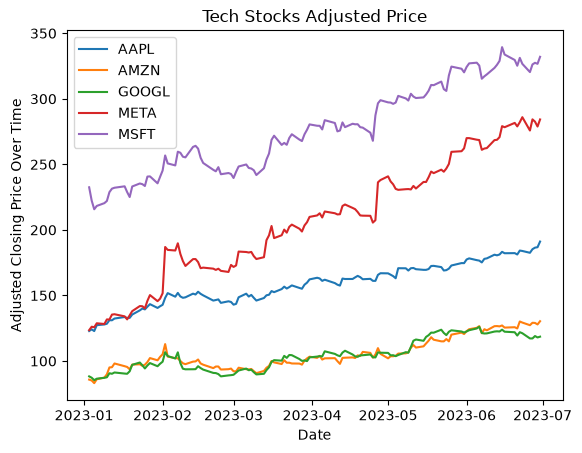

In [4]:
symbols = ['AAPL', 'AMZN', 'GOOGL', 'META', 'MSFT']
start_date = '2023-01-01'
end_date = '2023-07-01'
stock_data = yf.download(symbols, start=start_date, end=end_date)
stock_data.Close.to_csv('../../data/tech_stocks_2023.csv')   # backup copy of the prices, in case Yahoo changes or blocks the download
print(stock_data.head())

print(stock_data.Close.head()) # Close is already Adj.

# check: the labels must be in the same order as the data columns (yfinance sorts them alphabetically).
# My first version typed symbols in my own order (MSFT, AMZN, AAPL, ...) - the legend then labelled the wrong lines.
print(list(stock_data.Close.columns))   # the order of the data
print(symbols)                          # the order of my labels - must match

plt.plot(stock_data.Close)
plt.xlabel('Date')
plt.ylabel('Adjusted Closing Price Over Time')
plt.title('Tech Stocks Adjusted Price')
plt.legend(symbols)
plt.show()



### 4. Calculate and plot the daily simple rate of return over time.
Create a plot with matplotlib that shows the daily simple rate of return for each tech stock over time. Label the graph appropriately. 

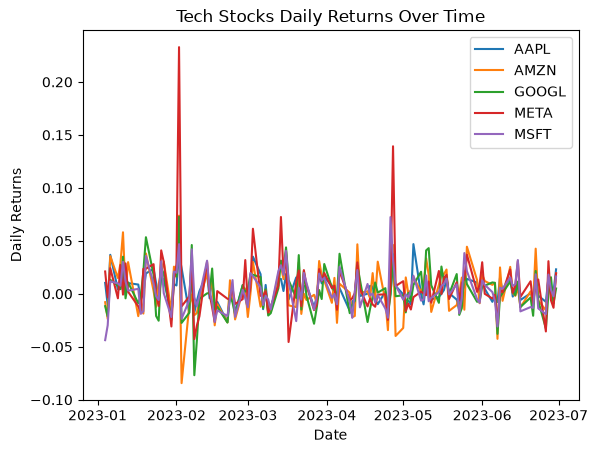

In [5]:
daily_returns = stock_data.Close.pct_change()
daily_returns.head()
plt.plot(daily_returns)
plt.xlabel('Date')
plt.ylabel('Daily Returns')
plt.title('Tech Stocks Daily Returns Over Time')
plt.legend(symbols)
plt.show()

### 5. Create subplots of daily simple rate of return.
In order to better visualize the daily returns, create a subplot for each tech stock. 

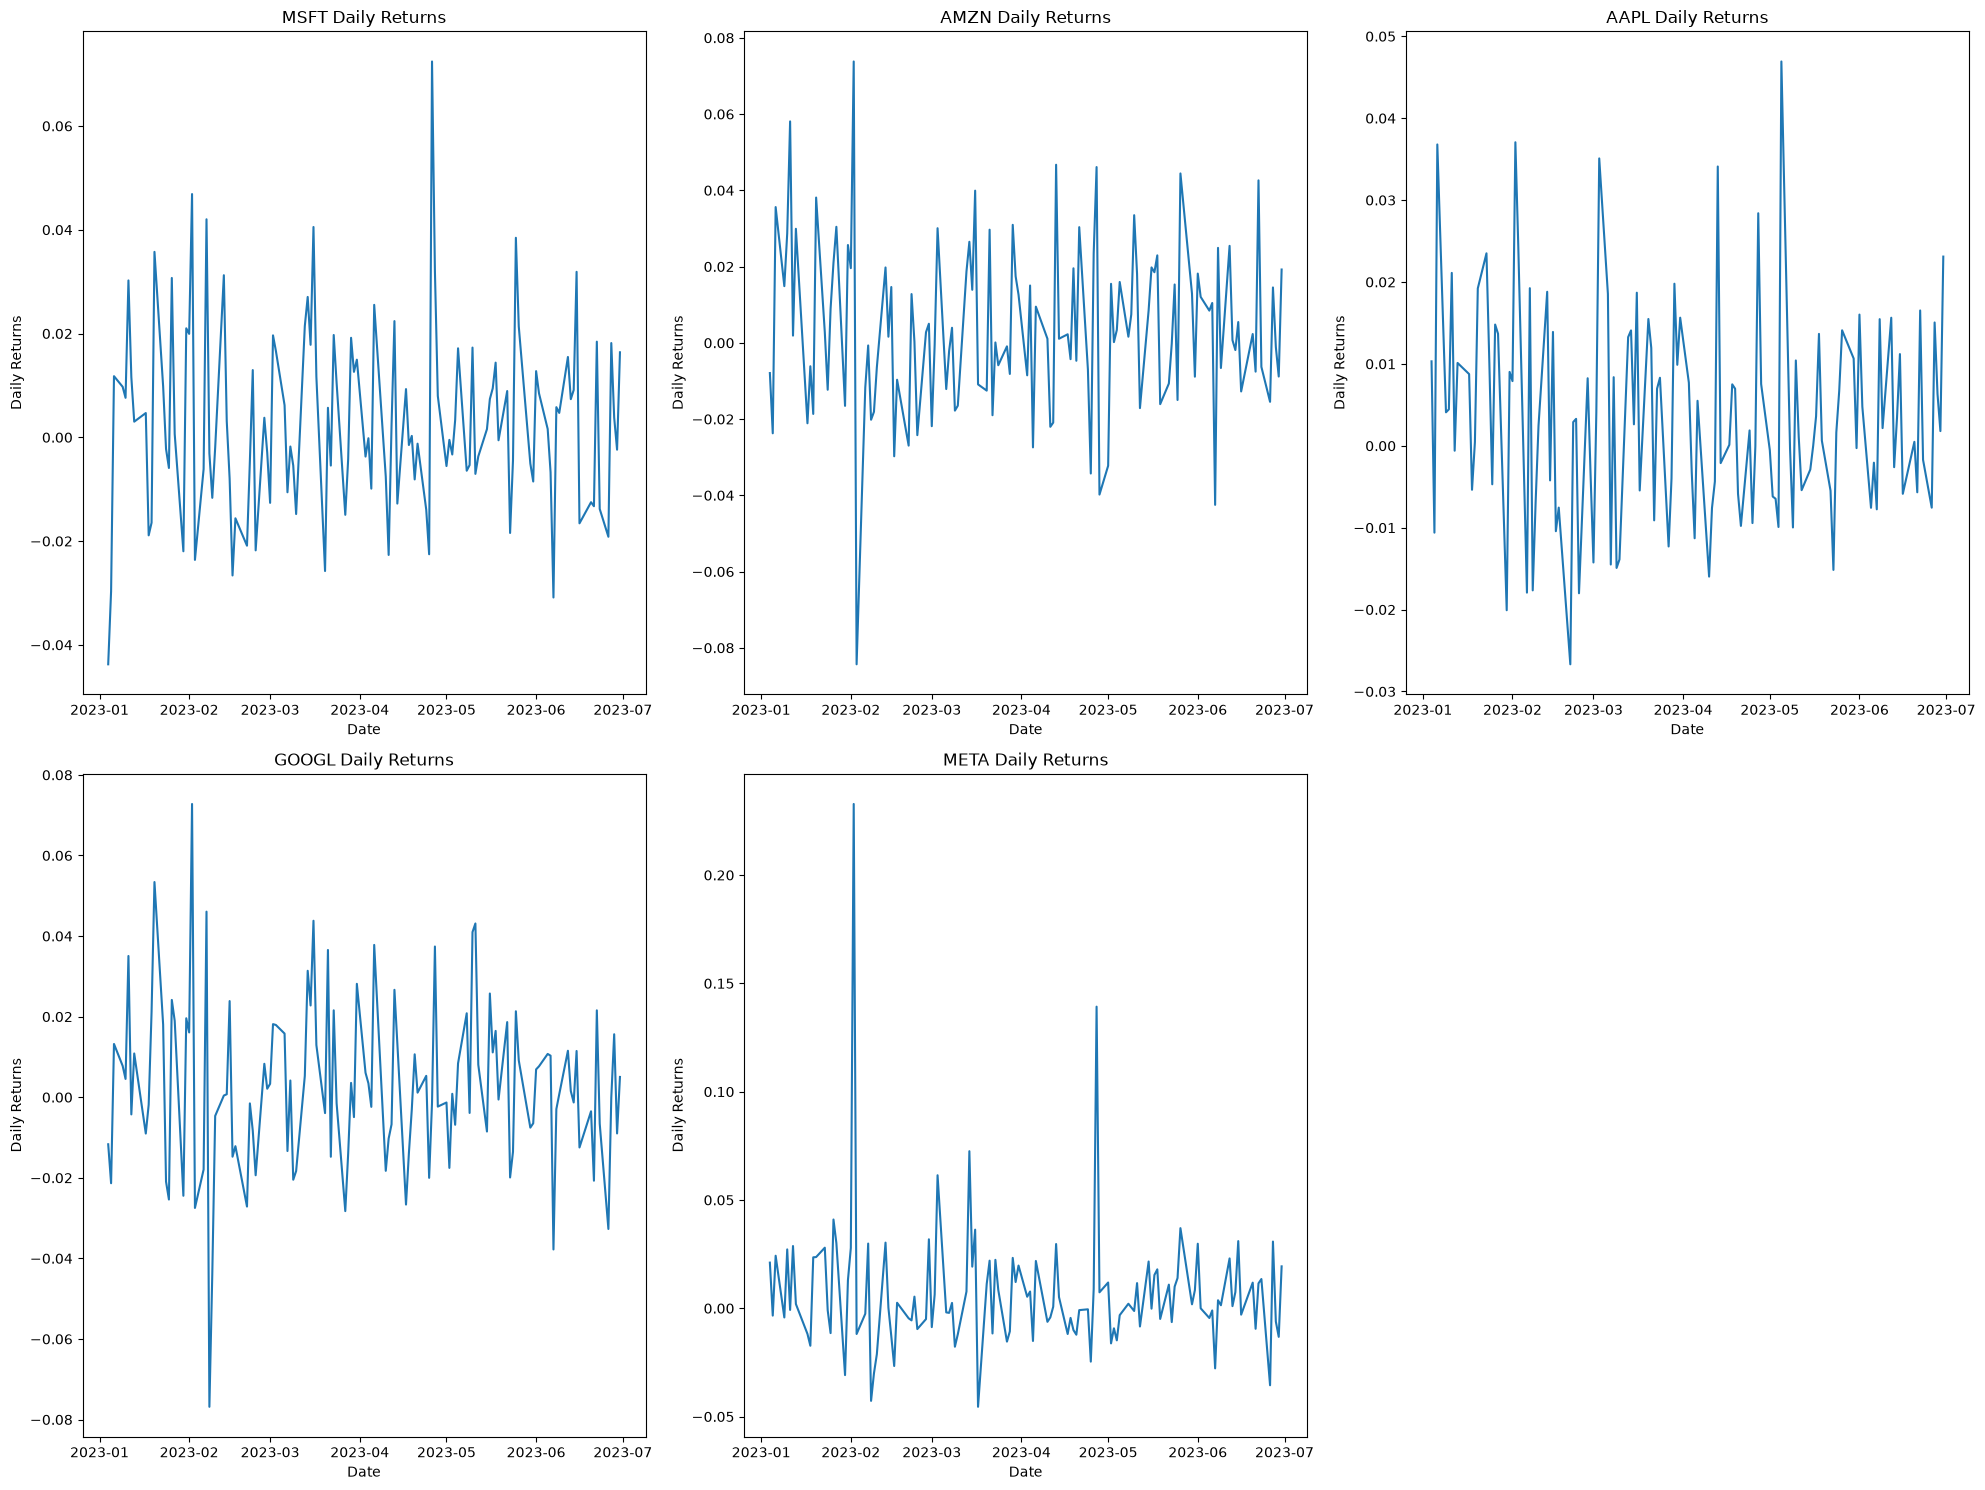

In [6]:
plt.figure(figsize=(20,15))
plt.subplot(2,3,1)
plt.plot(daily_returns['MSFT'])
plt.xlabel('Date')
plt.ylabel('Daily Returns')
plt.title('MSFT Daily Returns')

plt.subplot(2,3,2)
plt.plot(daily_returns['AMZN']) 
plt.xlabel('Date')
plt.ylabel('Daily Returns') 
plt.title('AMZN Daily Returns')

plt.subplot(2,3,3)
plt.plot(daily_returns['AAPL'])
plt.xlabel('Date')
plt.ylabel('Daily Returns')     
plt.title('AAPL Daily Returns')

plt.subplot(2,3,4)
plt.plot(daily_returns['GOOGL'])    
plt.xlabel('Date')
plt.ylabel('Daily Returns') 
plt.title('GOOGL Daily Returns')

plt.subplot(2,3,5)
plt.plot(daily_returns['META'])
plt.xlabel('Date')
plt.ylabel('Daily Returns')
plt.title('META Daily Returns')

plt.tight_layout()   
plt.show()


### 6. Calculate and plot the mean of each tech stock's daily simple rate of return

#### Step 1: Calculate mean rate of return
For each stock, calculate the mean daily simple rate of return.
#### Step 2: Plot bar chart
Use matplotlib to create a bar chart comparing the mean daily simple rate of return for each stock. Label the chart appropriately. 
#### Step 3: Analyze mean rate of return
Based on the mean rate of return, which stock would be the best option to invest in?

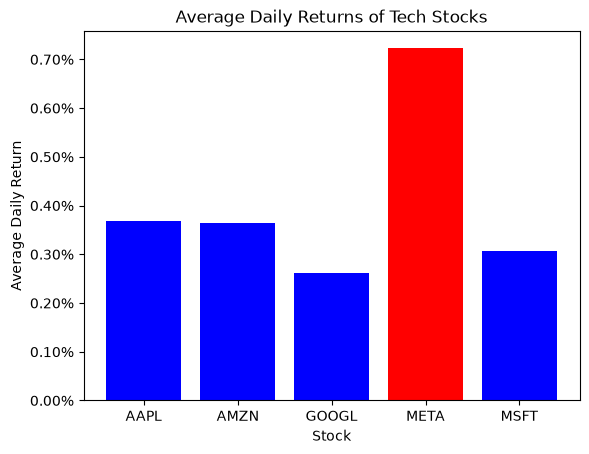

In [7]:
mean_returns = daily_returns.mean()                 # average daily return of each stock

ax = plt.gca()                                      # gca = "get current axes": the chart you're drawing on
ax.yaxis.set_major_formatter(PercentFormatter(1.0)) # 1.0 = "my data is a share of 1", so 0.02 -> 2%

colors = ['red' if v == mean_returns.max() else 'blue' for v in mean_returns]  # red for the highest mean, blue for the rest

plt.bar(mean_returns.index, mean_returns, color=colors)
plt.title('Average Daily Returns of Tech Stocks')
plt.xlabel('Stock')
plt.ylabel('Average Daily Return')
plt.show()

**Answer:** the red bar marks the highest average daily return - the best option by mean return alone.

### 7. Calculate and plot the variance.

#### Step 1: Calculate the variance
For each stock, calculate the variance of the mean daily simple rate of return.
#### Step 2: Plot bar chart
Use matplotlib to create a bar chart comparing the variance for each stock. Label the chart appropriately. 
#### Step 3: Analyse the variance
Based on the variance, which stock would be the riskiest to invest in?

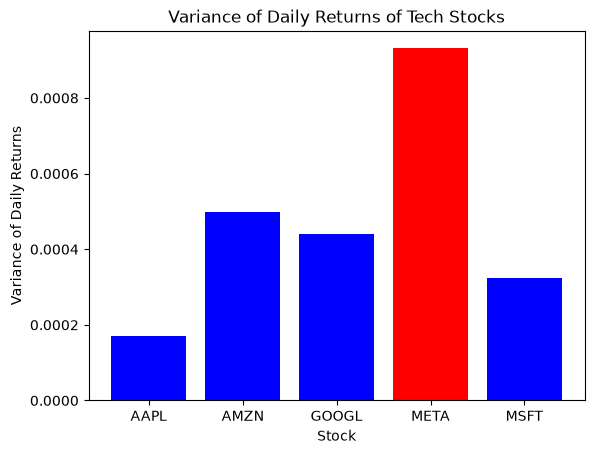

In [8]:
variance = daily_returns.var()

colors = ['red' if v == variance.max() else 'blue' for v in variance]  # red for the highest variance, blue for the rest

plt.bar(variance.index, variance, color=colors)
plt.title('Variance of Daily Returns of Tech Stocks')
plt.xlabel('Stock')
plt.ylabel('Variance of Daily Returns')
plt.show()


**Answer:** the red bar marks the highest variance - the riskiest stock.

### 8. Calculate and plot the standard deviation

#### Step 1: Calculate the standard deviation
For each stock, calculate the standard deviation of the mean daily simple rate of return.

#### Step 2: Plot the bar chart
Use matplotlib to create a bar chart comparing the standard deviation of the mean daily simple rate of return of each stock. Label the chart appropriately. 

#### Step 3: Analyze the standard deviation
Based on the standard deviation of the rates of return, which stock would you choose to invest in and why?

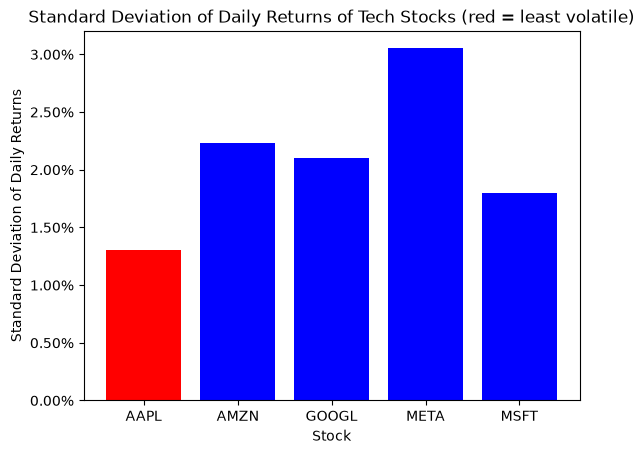

In [9]:
std_returns = daily_returns.std()                   # standard deviation of each stock's daily returns

ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

colors = ['red' if v == std_returns.min() else 'blue' for v in std_returns]  # red for the LOWEST std, blue for the rest

plt.bar(std_returns.index, std_returns, color=colors)
plt.title('Standard Deviation of Daily Returns of Tech Stocks (red = least volatile)')
plt.xlabel('Stock')
plt.ylabel('Standard Deviation of Daily Returns')
plt.show()

**Answer:** the red bar marks the lowest standard deviation - the least volatile stock, the one I'd choose on risk alone.

### 9. Calculate the correlations
Calculate the correlations between each of the stocks. Which stocks are positively correlated? Which are negatively correlated? Which have little correlation?

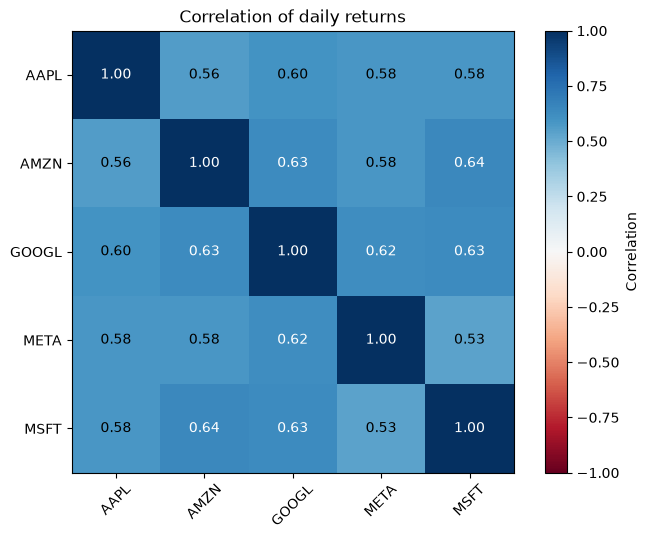

In [10]:
returns_corr = daily_returns.corr()
plt.figure(figsize=(8, 6.5))
plt.imshow(returns_corr, cmap='RdBu', vmin=-1, vmax=1)    
plt.colorbar(label='Correlation')                         
plt.xticks(range(len(symbols)), symbols, rotation=45)   
plt.yticks(range(len(symbols)), symbols)                
for i in range(len(symbols)):                            # i = row number 0 ... 4
    for j in range(len(symbols)):                        # j = column number 0 ... 4 (loop inside a loop: 25 squares)
        value = returns_corr.iloc[i, j]                   # the number in row i, column j
        plt.text(j, i, f'{value:.2f}', ha='center', va='center',   # write it in the square: x = column j, y = row i,
                 color='white' if abs(value) > 0.6 else 'black')   # centred; white text on dark squares (one-line if)
plt.title('Correlation of daily returns')
plt.subplots_adjust(bottom=0.2)                           # room at the bottom for the tilted names
plt.show()

All five stocks are positively correlated (about 0.53–0.64): big tech moves together. MSFT–AMZN move most alike, META–MSFT least. None are negatively correlated, so combining these five gives little diversification.